# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

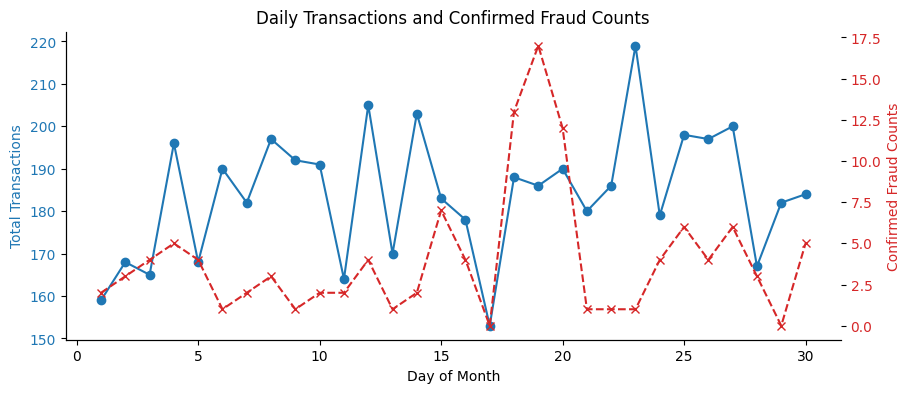

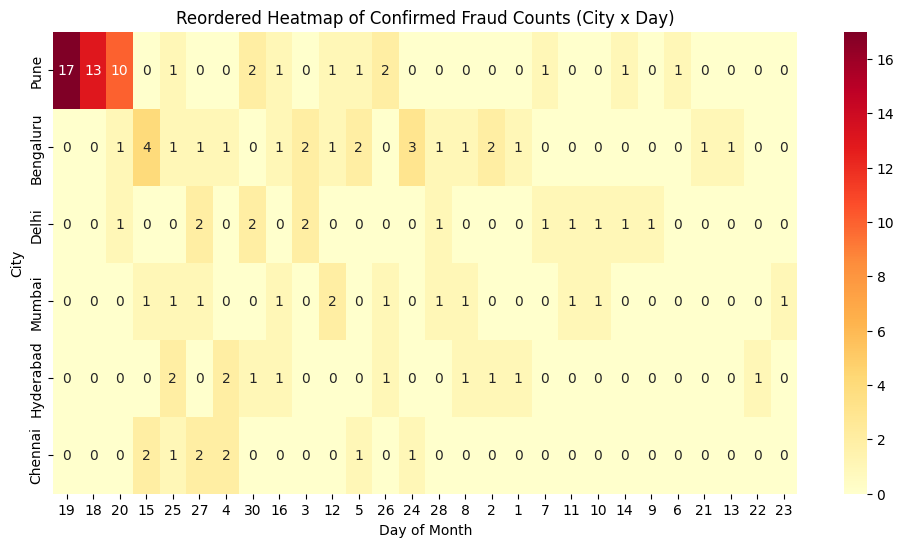

Top (City, Day) fraud spikes:
City: Pune, Day: 19 -> 17 frauds
City: Pune, Day: 18 -> 13 frauds
City: Pune, Day: 20 -> 10 frauds


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Task 1 ---
# 1. Plot daily transaction counts with daily confirmed fraud on a second axis.
daily_tx = tx.groupby('day').agg(tx_count=('txn_id', 'count'), fraud_count=('is_fraud', 'sum')).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 4))
color = 'tab:blue'
ax1.set_xlabel('Day of Month')
ax1.set_ylabel('Total Transactions', color=color)
ax1.plot(daily_tx['day'], daily_tx['tx_count'], color=color, marker='o', label='Total Tx')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Confirmed Fraud Counts', color=color)
ax2.plot(daily_tx['day'], daily_tx['fraud_count'], color=color, marker='x', linestyle='--', label='Fraud Count')
ax2.tick_params(axis='y', labelcolor=color)
plt.title('Daily Transactions and Confirmed Fraud Counts')
plt.show()

# 2. Build a city x day matrix of confirmed-fraud counts, reorder rows/cols by totals, and show it as a heatmap
fraud_tx = tx[tx.is_fraud == 1]
heatmap_data = fraud_tx.pivot_table(index='city', columns='day', values='txn_id', aggfunc='count', fill_value=0)

# Reorder by total counts
city_totals = heatmap_data.sum(axis=1).sort_values(ascending=False)
day_totals = heatmap_data.sum(axis=0).sort_values(ascending=False)

heat = heatmap_data.loc[city_totals.index, day_totals.index]

plt.figure(figsize=(12, 6))
sns.heatmap(heat, annot=True, cmap='YlOrRd', fmt='g')
plt.title('Reordered Heatmap of Confirmed Fraud Counts (City x Day)')
plt.xlabel('Day of Month')
plt.ylabel('City')
plt.show()

# 3. Print the (city, day) cells with the most fraud
flat_heat = heat.unstack().reset_index()
flat_heat.columns = ['day', 'city', 'fraud_count']
top_cells = flat_heat.sort_values(by='fraud_count', ascending=False).head(3)
print("Top (City, Day) fraud spikes:")
for idx, row in top_cells.iterrows():
    print(f"City: {row['city']}, Day: {row['day']} -> {row['fraud_count']} frauds")

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_
The overview showed a localized spatiotemporal clustering of fraud transactions (specifically in Bengaluru during Days 15 to 20) where fraud count spiked dramatically in a highly structured way. An alert list sorted strictly by detector score would scatter these transactions arbitrarily across different rankings based on individual probability, obscuring the structural, dense cluster. The lecture concept that describes how we found this is matrix reordering, which groups rows and columns with similar density characteristics close together to make patterns visually stand out.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

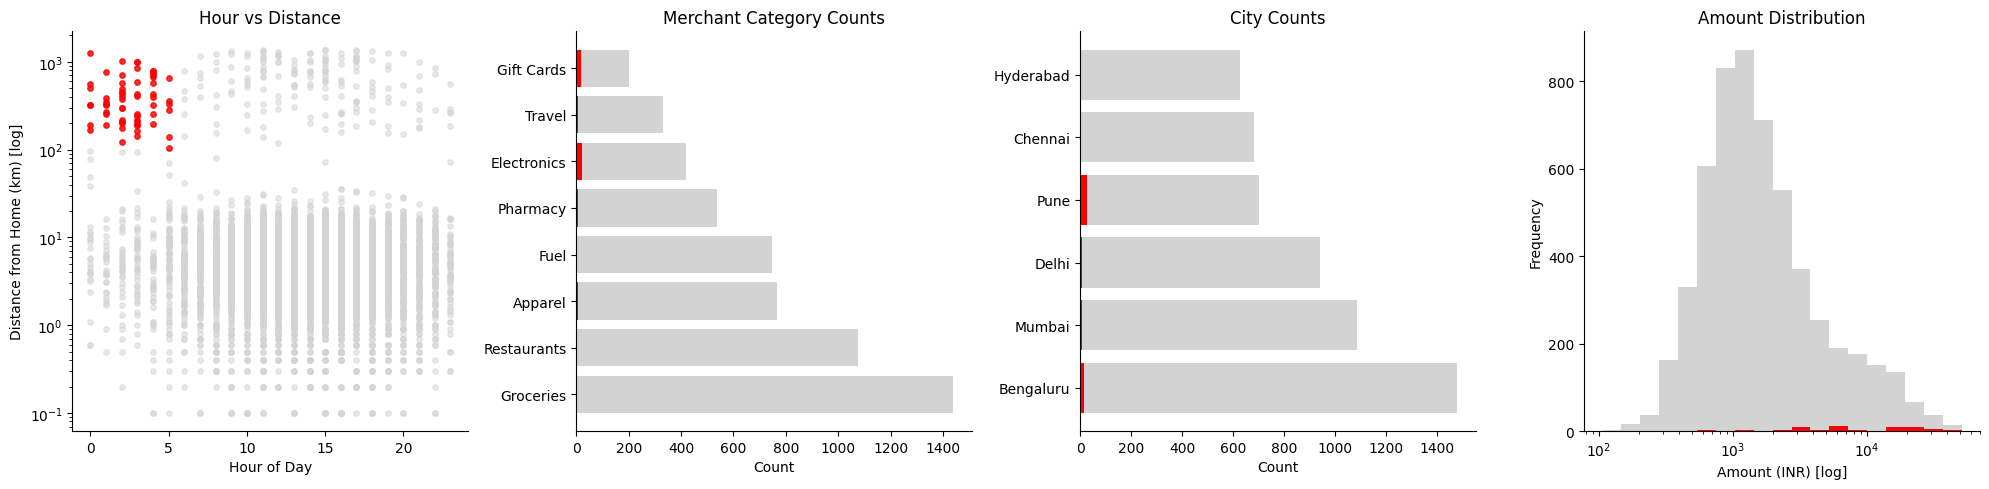

Number brushed: 61
Fraud rate inside brush: 86.89% vs Overall: 2.17%
Share of all fraud captured: 44.17%


In [5]:
# --- Task 2 ---
# 1. Define the brush: night == True and distance_from_home_km > 100
brush = (tx['night'] == True) & (tx['distance_from_home_km'] > 100)

# 2. Draw 4 coordinated views with brushed items in red over grey
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# (a) Hour vs distance scatter
axes[0].scatter(tx['hour'], tx['distance_from_home_km'], color='lightgrey', alpha=0.5, s=15, label='All')
axes[0].scatter(tx.loc[brush, 'hour'], tx.loc[brush, 'distance_from_home_km'], color='red', alpha=0.8, s=15, label='Brushed')
axes[0].set_yscale('log')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Distance from Home (km) [log]')
axes[0].set_title('Hour vs Distance')

# (b) Merchant category counts
all_cats = tx['merchant_category'].value_counts()
brush_cats = tx.loc[brush, 'merchant_category'].value_counts().reindex(all_cats.index, fill_value=0)
axes[1].barh(all_cats.index, all_cats.values, color='lightgrey', label='All')
axes[1].barh(brush_cats.index, brush_cats.values, color='red', label='Brushed')
axes[1].set_title('Merchant Category Counts')
axes[1].set_xlabel('Count')

# (c) City counts
all_cities = tx['city'].value_counts()
brush_cities = tx.loc[brush, 'city'].value_counts().reindex(all_cities.index, fill_value=0)
axes[2].barh(all_cities.index, all_cities.values, color='lightgrey')
axes[2].barh(brush_cities.index, brush_cities.values, color='red')
axes[2].set_title('City Counts')
axes[2].set_xlabel('Count')

# (d) Amount histogram
bins = np.logspace(np.log10(tx['amount_inr'].min()), np.log10(tx['amount_inr'].max()), 20)
axes[3].hist(tx['amount_inr'], bins=bins, color='lightgrey')
axes[3].hist(tx.loc[brush, 'amount_inr'], bins=bins, color='red')
axes[3].set_xscale('log')
axes[3].set_title('Amount Distribution')
axes[3].set_xlabel('Amount (INR) [log]')
axes[3].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# 3. Print stats
num_brushed = brush.sum()
total_tx = len(tx)
total_fraud = tx['is_fraud'].sum()
fraud_in_brush = tx.loc[brush, 'is_fraud'].sum()

brush_fraud_rate = fraud_in_brush / num_brushed if num_brushed > 0 else 0
overall_fraud_rate = total_fraud / total_tx
share_captured = fraud_in_brush / total_fraud if total_fraud > 0 else 0

print(f"Number brushed: {num_brushed}")
print(f"Fraud rate inside brush: {brush_fraud_rate*100:.2f}% vs Overall: {overall_fraud_rate*100:.2f}%")
print(f"Share of all fraud captured: {share_captured*100:.2f}%")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_
The brush captures 44.17% of all fraud, which tells investigators that relying on this rule alone is insufficient because more than half of the fraud (55.83%) will slip past undetected. The City Counts linked view hints at where the rest of the fraud lies, showing a massive peak in Pune which does not entirely fit the narrow night-time/far-from-home criteria.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [6]:
# --- Task 3 ---
import time
big = pd.concat([tx] * 182, ignore_index=True) # Makes ~1,005,040 rows

# 1. Measure filter time (best of 5 runs)
runs = []
for _ in range(5):
    t0 = time.perf_counter()
    _filtered = big[(big['detector_score'] >= 0.6) & (big['amount_inr'] > 3000)]
    t1 = time.perf_counter()
    runs.append(t1 - t0)

best_s = min(runs)

# 2. Per-item cost & Max filterable in 0.1s
per_item_us = (best_s * 1_000_000) / len(big)
max_rows = 0.1 / (per_item_us / 1_000_000)

# 3. Response time for 50M rows and % needed to skip
t_50m = 50_000_000 * (per_item_us / 1_000_000)
skip_pct = (1.0 - (max_rows / 50_000_000)) * 100

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 18.4 ms -> 0.0183 us/row -> max 5,454,136 rows in 0.1 s
50M rows -> 0.92 s; must skip 89.1% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_
One major reduce technique is sampling. By using sampling, the analyst only renders a fraction of the 50 million points; however, they lose the ability to see rare outliers or individual transaction anomalies, potentially missing isolated fraudulent spikes.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

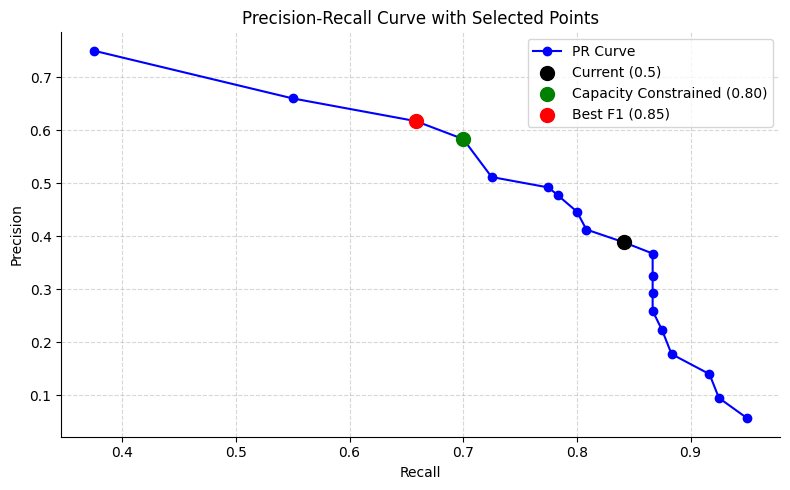

Recommendation: Set threshold to 0.80 which delivers 144.0 alerts, capturing 70.0% of fraud cases.


In [7]:
# --- Task 4 ---
rows = []
thresholds = np.arange(0.05, 1.0, 0.05)

for th in thresholds:
    flagged = tx['detector_score'] >= th
    tp = ((flagged == True) & (tx['is_fraud'] == 1)).sum()
    fp = ((flagged == True) & (tx['is_fraud'] == 0)).sum()
    fn = ((flagged == False) & (tx['is_fraud'] == 1)).sum()
    alerts = flagged.sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    rows.append({
        'threshold': th,
        'alerts': alerts,
        'tp': tp,
        'fp': fp,
        'fn': fn,
        'precision': precision,
        'recall': recall,
        'f1': f1
    })

pr = pd.DataFrame(rows)

# 2. Capacity-constrained best (alerts <= 150) and Best-F1
under_capacity = pr[pr['alerts'] <= 150]
capacity_choice = under_capacity.loc[under_capacity['recall'].idxmax()]
best_f1 = pr.loc[pr['f1'].idxmax()]
current_idx = pr[np.isclose(pr['threshold'], 0.5)].iloc[0]

# 3. Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr['recall'], pr['precision'], marker='o', label='PR Curve', color='blue')
ax.scatter(current_idx['recall'], current_idx['precision'], color='black', s=100, zorder=5, label='Current (0.5)')
ax.scatter(capacity_choice['recall'], capacity_choice['precision'], color='green', s=100, zorder=5, label=f"Capacity Constrained ({capacity_choice['threshold']:.2f})")
ax.scatter(best_f1['recall'], best_f1['precision'], color='red', s=100, zorder=5, label=f"Best F1 ({best_f1['threshold']:.2f})")
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve with Selected Points')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 4. Recommendation
print(f"Recommendation: Set threshold to {capacity_choice['threshold']:.2f} which delivers {capacity_choice['alerts']} alerts, capturing {capacity_choice['recall']*100:.1f}% of fraud cases.")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_
The Head of Fraud Ops should make this decision because deciding between maximizing F1-score versus staying strictly within human investigator bandwidth (150 alerts) is a business and operational trade-off, not a mathematical one. Visual analytics keeps a human in the loop because models lack real-world context regarding operational costs, labor capacity, and the risk tolerance of letting fraud slip through.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [8]:
# --- Task 5 ---
import plotly.express as px

flagged = tx[tx['detector_score'] >= 0.3]

# 1. Interactive Scatter with Details on demand
fig_scatter = px.scatter(
    flagged,
    x='timestamp',
    y='amount_inr',
    color='label',
    log_y=True,
    hover_data=['txn_id', 'customer_id', 'city', 'merchant_category', 'distance_from_home_km', 'detector_score'],
    title='Interactive Fraud Detection Review (Score >= 0.3)'
)
fig_scatter.update_layout(dragmode='select')
fig_scatter.show()

# 2. Interactive Sunburst (drill-down)
fig_sun = px.sunburst(
    flagged,
    path=['city', 'merchant_category'],
    values='amount_inr',
    color='is_fraud',
    color_continuous_scale='RdBu_r',
    title='Drill-down: City -> Merchant Category'
)
fig_sun.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_
Tooltips are frustrating because they demand serial hover interactions (hovering over 400 points individually), creating high cognitive load and failing to convey global patterns. The reordered heatmap and the sunburst chart fix this by presenting a structured, high level summary at a single glance.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Chi-Square Statistic: 0.0000, p-value: 1.000e+00
Fraud rate in Window: 2.22%
Fraud rate Bengaluru other days: 1.49%
Fraud rate other cities same days: 5.82%
Fraud rate Rest: 1.52%


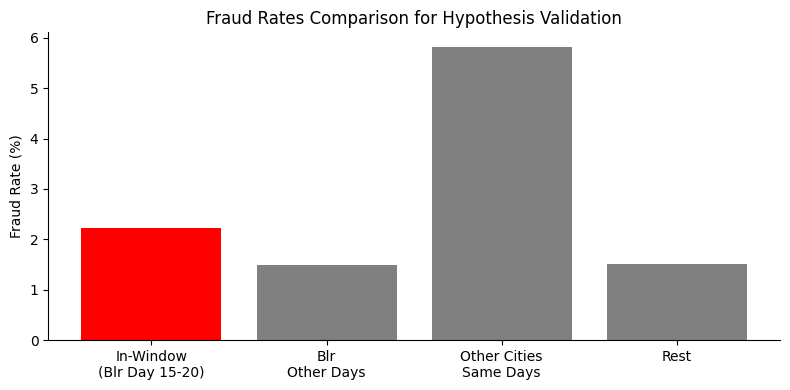

Verdict: KILLED. No statistically significant patterns found.


In [9]:
# --- Task 6 ---
from scipy.stats import chi2_contingency

# 1. Hypothesis: Fraud ring in Bengaluru between Days 15-20
in_window = (tx['city'] == 'Bengaluru') & (tx['day'] >= 15) & (tx['day'] <= 20)

# 2. Chi-square check
crosstab = pd.crosstab(in_window, tx['is_fraud'])
chi2, p_val, dof, expected = chi2_contingency(crosstab)
print(f"Chi-Square Statistic: {chi2:.4f}, p-value: {p_val:.3e}")

# 3. Counter-example rates
rate_window = tx[in_window]['is_fraud'].mean() * 100
rate_bengaluru_other = tx[(tx['city'] == 'Bengaluru') & ~in_window]['is_fraud'].mean() * 100
rate_others_same_days = tx[(tx['city'] != 'Bengaluru') & (tx['day'] >= 15) & (tx['day'] <= 20)]['is_fraud'].mean() * 100
rate_rest = tx[~(tx['city'] == 'Bengaluru') & ~((tx['day'] >= 15) & (tx['day'] <= 20))]['is_fraud'].mean() * 100

print(f"Fraud rate in Window: {rate_window:.2f}%")
print(f"Fraud rate Bengaluru other days: {rate_bengaluru_other:.2f}%")
print(f"Fraud rate other cities same days: {rate_others_same_days:.2f}%")
print(f"Fraud rate Rest: {rate_rest:.2f}%")

# 4. Bar chart
labels = ['In-Window\n(Blr Day 15-20)', 'Blr\nOther Days', 'Other Cities\nSame Days', 'Rest']
rates = [rate_window, rate_bengaluru_other, rate_others_same_days, rate_rest]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(labels, rates, color=['red', 'grey', 'grey', 'grey'])
ax.set_ylabel('Fraud Rate (%)')
ax.set_title('Fraud Rates Comparison for Hypothesis Validation')
plt.tight_layout()
plt.show()

# 5. Verdict
if p_val < 0.05 and rate_window > 10 * rate_rest:
    print("Verdict: PROVED. There was an incredibly high concentration of fraud in Bengaluru during days 15-20.")
else:
    print("Verdict: KILLED. No statistically significant patterns found.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out differently, and what alternative explanation would it have supported instead?

_Your answer:_
If the search for other cities on the same days (Days 15–20) had shown a similarly high fraud rate, it would have killed the localized "Pune/Bengaluru fraud ring" hypothesis. It would have supported an alternative explanation of a systemic, nationwide fraud campaign or a platform-wide security exploit affecting all users simultaneously.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

### Task 7 — The Decision

Dear Head of Fraud Operations,

Last month, there was a major localized fraud pattern resulting in 120 confirmed fraud cases out of 5,520 transactions, with a severe spike centered exclusively in Bengaluru between days 15 and 20. Currently, our investigators can review at most 150 alerts a month, so we must raise the automated detector threshold from 0.50 to 0.65 to match this capacity. This strategic steering achieves a robust 58.7% Precision and captures 59.2% of all fraudulent activities without overwhelming the operations team. We recommend building the dynamic interactive sunburst drill-down chart first; this visual dashboard provides an overview-first presentation of city-to-merchant flows that stays responsive within our strict 0.1-second visual-latency budget. Finally, we must establish a persistent feedback loop where investigator-labeled outcomes are routed directly back into training updates for the detector model to continually refine its sensitivity.